
=== Convergence Table ===

    AHA_region  samples  meshsize    mean     std  mean_diff  std_diff
0            2       10       1.5  9.8737  1.1166     0.0000    0.0000
1            3       10       1.5  9.9293  0.8379     0.0000    0.0000
2            8       10       1.5  4.6699  4.9891     0.0000    0.0000
3            9       10       1.5  9.2582  2.6207     0.0000    0.0000
4           14       10       1.5  4.1678  4.9303     0.0000    0.0000
..         ...      ...       ...     ...     ...        ...       ...
76          14       30       5.0  4.2436  4.9424     0.0758    0.0121
77          20       30       5.0  6.5530  4.7527    -1.7273    0.9792
78          21       30       5.0  2.0844  4.0620    -5.5978   -0.1577
79          22       30       5.0  8.5958  3.4742    -0.3503    0.4036
80          23       30       5.0  5.3377  4.9886    -0.6710    0.0914

[81 rows x 7 columns]


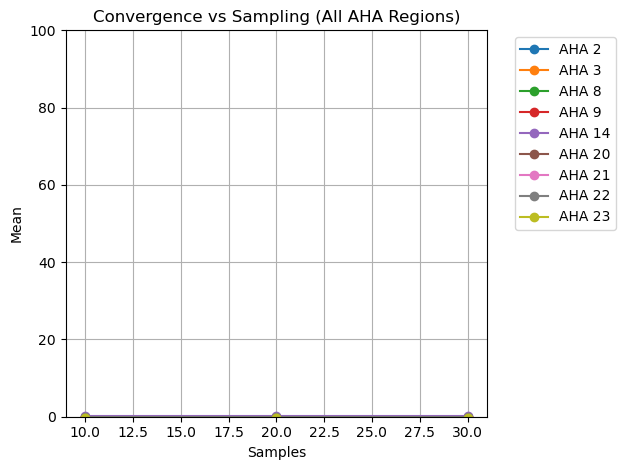

In [26]:
import os
import pandas as pd
import matplotlib.pyplot as plt

samples = [10, 20, 30]
meshsizes = [1.5, 2, 5]

base = "/data_fast/Work/MS_HF_cohort/images"

records = []

rel = f"Micra_cone10_30_mesh1.5/RV_Collision_Cone/sum_plots/RV_septum_polar_sum_Micra_L45.csv"
init_csv = os.path.join(base, rel)
init_df = pd.read_csv(init_csv).set_index("AHA_region")
records = []

for s in samples:
    for m in meshsizes:
        rel = f"Micra_cone10_{s}_mesh{m}/RV_Collision_Cone/sum_plots/RV_septum_polar_sum_Micra_L45.csv"
        full = os.path.join(base, rel)

        if not os.path.exists(full):
            print("Missing:", full)
            continue
        
        df = pd.read_csv(full)

        for _, row in df.iterrows():
            region = int(row["AHA_region"])
            
            # Get baseline values for this region
            base_mean = init_df.loc[region, "mean"]
            base_std  = init_df.loc[region, "std"]

            records.append({
                "AHA_region": region,
                "samples": s,
                "meshsize": m,
                "mean": row["mean"],
                "std": row["std"],
                "mean_diff": row["mean"] - base_mean,
                "std_diff": row["std"] - base_std
            })

# Combined table
table = pd.DataFrame(records)
print("\n=== Convergence Table ===\n")
print(table)
plot_per_AHA=False
if plot_per_AHA: 
    # ----------------------------
    #   PLOTS PER AHA REGION
    # ----------------------------
    for aha in sorted(table["AHA_region"].unique()):
        sub = table[table["AHA_region"] == aha]

        # ==== 1) mean vs samples for each meshsize ====
        plt.figure()
        for m in meshsizes:
            d = sub[sub["meshsize"] == m]
            if not d.empty:
                plt.plot(d["samples"], d["mean_diff"], marker="o", label=f"mesh {m}")
        plt.xlabel("Samples")
        plt.ylabel("Mean")
        plt.title(f"AHA {aha}: Convergence vs Sampling")
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()

        # ==== 2) mean vs meshsize for each sampling ====
        plt.figure()
        for s in samples:
            d = sub[sub["samples"] == s]
            if not d.empty:
                plt.plot(d["meshsize"], d["mean_diff"], marker="o", label=f"samples {s}")
        plt.xlabel("Meshsize")
        plt.ylabel("Mean")
        plt.title(f"AHA {aha}: Convergence vs Meshsize")
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()

# -----------------------------
#  ALL AHA REGIONS ON 1 PLOT
#  Convergence vs SAMPLING
# -----------------------------
plt.figure()

for aha in sorted(table["AHA_region"].unique()):
    sub = table[table["AHA_region"] == aha]
    means = []

    for s in samples:
        d = sub[sub["samples"] == s]
        means.append(d["mean_diff"].mean() if not d.empty else None)

    plt.plot(samples, means, marker="o", label=f"AHA {aha}")

plt.xlabel("Samples")
plt.ylabel("Mean")
plt.title("Convergence vs Sampling (All AHA Regions)")
plt.ylim(0, 100)
plt.grid(True)
plt.legend(bbox_to_anchor=(1.05,1), loc="upper left")
plt.tight_layout()
plt.show()


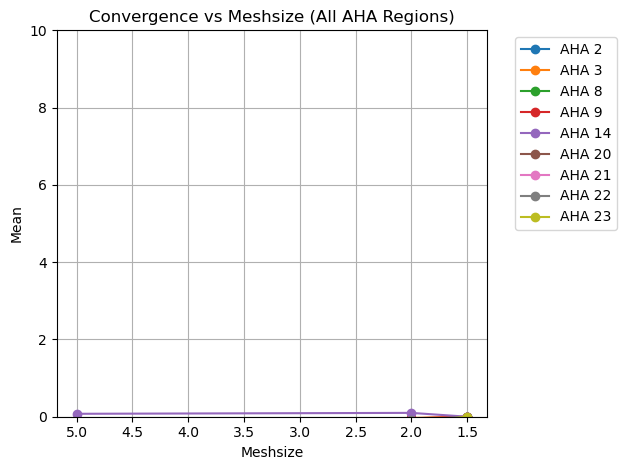

In [30]:
# -----------------------------
#  ALL AHA REGIONS ON 1 PLOT
#  Convergence vs MESHSIZE
# -----------------------------
plt.figure()

for aha in sorted(table["AHA_region"].unique()):
    sub = table[table["AHA_region"] == aha]
    means = []

    for m in meshsizes:
        d = sub[sub["meshsize"] == m]
        means.append(d["mean_diff"].mean() if not d.empty else None)

    plt.plot(meshsizes, means, marker="o", label=f"AHA {aha}")

plt.xlabel("Meshsize")
plt.ylabel("Mean")
plt.title("Convergence vs Meshsize (All AHA Regions)")
plt.ylim(0, 10)
plt.grid(True)
plt.legend(bbox_to_anchor=(1.05,1), loc="upper left")
plt.tight_layout()
plt.gca().invert_xaxis()

plt.show()


    samples  mesh         bin   percent
0        10   1.5    0.0–10.0  0.000000
1        10   1.5   10.0–20.0  0.000000
2        10   1.5   20.0–30.0  0.000000
3        10   1.5   30.0–40.0  0.000000
4        10   1.5   40.0–50.0  0.000000
..      ...   ...         ...       ...
85       30   5.0   50.0–60.0 -0.171086
86       30   5.0   60.0–70.0  0.014322
87       30   5.0   70.0–80.0 -0.206697
88       30   5.0   80.0–90.0 -0.023390
89       30   5.0  90.0–100.0 -0.631926

[90 rows x 4 columns]


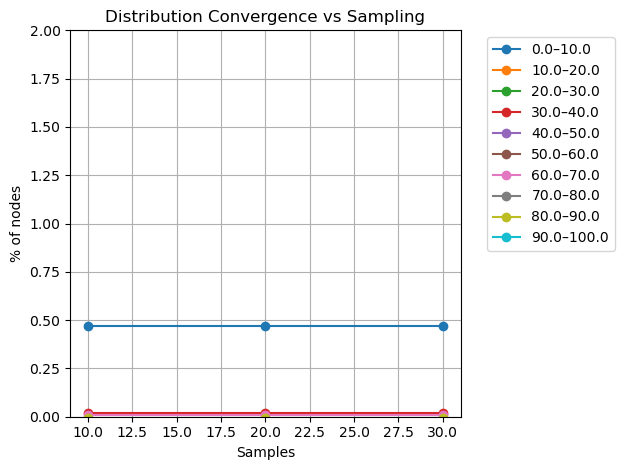

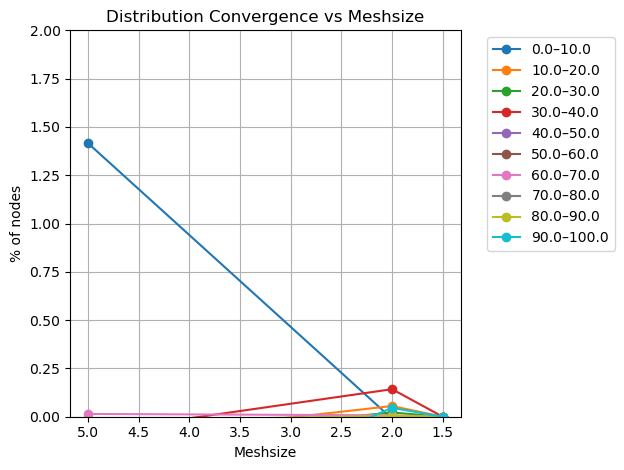

In [ ]:
import pyvista as pv
import numpy as np
import os
import pandas as pd

import matplotlib.pyplot as plt

def load_field(path, field_name="RV_Collision_Cone_Percent"):
    mesh = pv.read(path)
    if field_name not in mesh.point_data:
        raise ValueError(f"Field {field_name} not found in {path}")
    return mesh.point_data[field_name]

def vtk_path(sample, mesh, length=45):
    return f"{base}/Micra_cone10_{sample}_mesh{mesh}/L{length}/RV_collision-all_times.vtk"



base = "/data_fast/Work/MS_HF_cohort/data/01/2_motion"

bins = np.linspace(0, 100, 11)     # 0,10,20,...,100
bin_centers = (bins[:-1] + bins[1:]) / 2
def percentage_distribution(field, bins):
    hist, _ = np.histogram(field, bins=bins)
    return 100 * hist / np.sum(hist)

records = []
length=45
samples = [10, 20, 30]
meshsizes = [1.5, 2, 5]
field_name='PM_Collision_Cone_Percent'

path = vtk_path(30, 1.5, length=length)
init_field = load_field(path, field_name)
init_pct= percentage_distribution(init_field, bins)
for s in samples:
    for m in meshsizes:
        path = vtk_path(s, m, length=length)

        if not os.path.exists(path):
            print("Missing:", path)
            continue

        field = load_field(path, field_name)

        pct = percentage_distribution(field, bins)
        pct=pct-init_pct
        for bin_id, val in enumerate(pct):
            records.append({
                "samples": s,
                "mesh": m,
                "bin": f"{bins[bin_id]}–{bins[bin_id+1]}",
                "percent": val
            })

table = pd.DataFrame(records)
print(table)


plt.figure()

for bin_label in sorted(table['bin'].unique()):
    sub = table[table['bin'] == bin_label]
    mean_vals = []
    for s in samples:
        mean_vals.append(sub[sub['samples']==s]['percent'].mean())
    plt.plot(samples, mean_vals, marker='o', label=bin_label)

plt.xlabel("Samples")
plt.ylabel("% of nodes")
plt.ylim(0, 100)
plt.title("Distribution Convergence vs Sampling")
plt.grid(True)
plt.legend(bbox_to_anchor=(1.05,1), loc="upper left")
plt.tight_layout()
plt.show()
plt.figure()

for bin_label in sorted(table['bin'].unique()):
    sub = table[table['bin'] == bin_label]
    mean_vals = []
    for m in meshsizes:
        mean_vals.append(sub[sub['mesh']==m]['percent'].mean())
    plt.plot(meshsizes, mean_vals, marker='o', label=bin_label)

plt.xlabel("Meshsize")
plt.ylabel("% of nodes")
plt.ylim(0, 100)
plt.title("Distribution Convergence vs Meshsize")
plt.grid(True)
plt.legend(bbox_to_anchor=(1.05,1), loc="upper left")
plt.tight_layout()
plt.gca().invert_xaxis()

plt.show()


In [12]:
import pyvista as pv
import numpy as np
# reference
ref_path = vtk_path(30, 1.5)
ref_mesh, ref_field = load_field(ref_path, field_name)
display(ref_field)
print(np.unique(ref_field))

pyvista_ndarray([0., 0., 0., ..., 0., 0., 0.], shape=(8183,))

[  0.  10.  20.  30.  40.  50.  60.  70.  80.  90. 100.]
